# Redistribution sensitivity

Assess culture, normalization, and label sensitivity of paired effects.


In [1]:
import os
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

from monopoly import MonopolyDataset, MonopolyModel
from monopoly import __version__ as monopoly_version

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
N_CPUS = min(4, os.cpu_count() or 1)
EXPECTED_MONOPOLY_VERSION = '0.1.0'
FRACTIONS = {
    'input': ('Input', 'input'),
    'monosome': ('Monosome', 'mono'),
    'polysome': ('Polysome', 'poly'),
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the primary analysis.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()

primary = pd.read_csv(
    RESULTS_DIR / 'polysomeMonosome.tsv',
    sep = '\t',
).set_index('geneId')
primary_diagnostics = pd.read_csv(
    RESULTS_DIR / 'polysomeMonosome.diagnostics.tsv',
    sep = '\t',
).set_index('geneId')

if monopoly_version != EXPECTED_MONOPOLY_VERSION:
    raise RuntimeError(
        f'Expected Monopoly {EXPECTED_MONOPOLY_VERSION}, found {monopoly_version}.'
    )
if not primary.index.equals(primary_diagnostics.index):
    raise ValueError('Primary results and diagnostics are not aligned.')
if primary_diagnostics['fitStatus'].eq('failed').any():
    raise ValueError('The primary result contains failed fits.')

leading_ids = primary.index[primary['adjustedPValue'].lt(ALPHA)]
display(pd.DataFrame({
    'participants': [len(metadata)],
    'genes': [len(primary)],
    'workingModelFdrGenes': [len(leading_ids)],
}))


,participants,genes,workingModelFdrGenes
0,6,20470,22


In [3]:
# Recover the fixed gene set used by the primary analysis.


def prepare_counts(folder: str, prefix: str):
    path = DATA_DIR / folder / 'salmon.merged.gene_counts_length_scaled.tsv'
    table = pd.read_csv(path, sep = '\t')
    columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]
    missing = {'gene_id', 'gene_name', *columns}.difference(table.columns)

    if missing:
        raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
    if table['gene_id'].isna().any() or not table['gene_id'].is_unique:
        raise ValueError(f'Gene identifiers must be complete and unique in {folder}.')

    table = table.set_index('gene_id')
    missing_genes = primary.index.difference(table.index)
    if not missing_genes.empty:
        raise ValueError(f'{folder} is missing {len(missing_genes)} modeled genes.')

    names = table.loc[primary.index, 'gene_name'].rename('geneName')
    counts = table.loc[primary.index, columns]
    values = counts.to_numpy(dtype = 'float64')

    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError(f'Counts must be finite and nonnegative in {folder}.')

    counts.columns = sample_ids
    counts = np.rint(counts.T).astype('int64')
    counts.index.name = 'sampleId'
    counts.columns.name = 'geneId'
    return counts, names


counts = {}
gene_names = {}

for fraction, (folder, prefix) in FRACTIONS.items():
    counts[fraction], gene_names[fraction] = prepare_counts(folder, prefix)

for fraction in ('monosome', 'polysome'):
    if not gene_names['input'].equals(gene_names[fraction]):
        raise ValueError(f'{fraction.title()} gene annotations are not aligned.')

if not primary['geneName'].equals(gene_names['input']):
    raise ValueError('Primary gene annotations do not match the count matrices.')

gene_metadata = primary[['geneName']].copy()


In [4]:
# Refit the same estimand under one controlled change.


def fit_redistribution(
    count_matrices: dict[str, pd.DataFrame],
    participant_metadata: pd.DataFrame,
    normalization: str,
):
    dataset = MonopolyDataset(
        input = count_matrices['input'],
        monosome = count_matrices['monosome'],
        polysome = count_matrices['polysome'],
        metadata = participant_metadata,
        gene_metadata = gene_metadata,
    )
    model = MonopolyModel(
        dataset = dataset,
        reference = REFERENCE,
    ).fit(
        normalization = normalization,
        fit_type = 'parametric',
        size_factor_fit_type = 'ratio',
        n_cpus = N_CPUS,
    )
    result = model.contrast(
        'poly',
        'mono',
        alpha = ALPHA,
        cooks_filter = False,
        independent_filter = True,
    )

    design = model.design_matrix
    diagnostics = result.diagnostics.set_index('geneId')
    table = result.table.set_index('geneId')

    if np.linalg.matrix_rank(design.to_numpy()) != design.shape[1]:
        raise ValueError('A sensitivity design matrix is not full rank.')
    if design.shape[0] - design.shape[1] <= 0:
        raise ValueError('A sensitivity design has no residual degrees of freedom.')
    if model.fit_summary['failedGenes']:
        raise RuntimeError('At least one sensitivity gene failed model fitting.')
    if not table.index.equals(primary.index):
        raise ValueError('A sensitivity result is not aligned to the primary result.')
    if not table.index.equals(diagnostics.index):
        raise ValueError('A sensitivity result and diagnostics are not aligned.')
    if not np.isfinite(table['log2FoldChange']).all():
        raise ValueError('A sensitivity result contains a nonfinite effect estimate.')

    return model, result


In [5]:
# Delete one participant at a time without refiltering genes.

leave_one_out_tables = []
leave_one_out_records = []

for omitted in sample_ids:
    retained = [sample_id for sample_id in sample_ids if sample_id != omitted]
    subset_counts = {
        fraction: matrix.loc[retained]
        for fraction, matrix in counts.items()
    }
    subset_metadata = metadata.loc[retained]
    model, result = fit_redistribution(
        subset_counts,
        subset_metadata,
        normalization = 'fraction',
    )
    table = result.table.set_index('geneId')
    delta = table['log2FoldChange'] - primary['log2FoldChange']
    complete = np.isfinite(table['log2FoldChange']) & np.isfinite(
        primary['log2FoldChange']
    )
    leading_concordant = np.sign(
        table.loc[leading_ids, 'log2FoldChange']
    ).eq(np.sign(primary.loc[leading_ids, 'log2FoldChange']))

    selected = table[[
        'geneName',
        'log2FoldChange',
        'log2FoldChangeSE',
        'statistic',
        'pValue',
    ]].reset_index()
    selected.insert(2, 'omittedCondition', str(metadata.loc[omitted, 'condition']))
    selected.insert(2, 'omittedParticipantId', omitted)
    leave_one_out_tables.append(selected)
    leave_one_out_records.append({
        'omittedParticipantId': omitted,
        'omittedCondition': str(metadata.loc[omitted, 'condition']),
        'participants': len(retained),
        'residualDegreesOfFreedom': (
            model.design_matrix.shape[0] - model.design_matrix.shape[1]
        ),
        'spearmanRho': spearmanr(
            primary.loc[complete, 'log2FoldChange'],
            table.loc[complete, 'log2FoldChange'],
        ).statistic,
        'medianAbsoluteLfcChange': delta.abs().median(),
        'percentile95AbsoluteLfcChange': delta.abs().quantile(0.95),
        'leadingGenes': len(leading_ids),
        'leadingDirectionConcordantGenes': int(leading_concordant.sum()),
        'leadingDirectionConcordance': leading_concordant.mean(),
    })

leave_one_out = pd.concat(leave_one_out_tables, ignore_index = True)
leave_one_out_summary = pd.DataFrame(leave_one_out_records)
display(leave_one_out_summary)


,omittedParticipantId,omittedCondition,participants,residualDegreesOfFreedom,spearmanRho,medianAbsoluteLfcChange,percentile95AbsoluteLfcChange,leadingGenes,leadingDirectionConcordantGenes,leadingDirectionConcordance
0,07c06,Unaffected,5,6,0.914745,0.172349,1.054512,22,22,1.0
1,07c13,Unaffected,5,6,0.852737,0.160902,1.019774,22,22,1.0
2,07c16,Unaffected,5,6,0.749878,0.230845,1.117804,22,22,1.0
3,1851,ASD,5,6,0.859112,0.205461,0.855957,22,22,1.0
4,1861,ASD,5,6,0.905028,0.130538,0.767977,22,22,1.0
5,1916,ASD,5,6,0.877949,0.172231,0.780432,22,22,1.0


In [6]:
# Summarize effect stability among the primary working-model discoveries.

leave_one_out_wide = leave_one_out.pivot(
    index = 'geneId',
    columns = 'omittedParticipantId',
    values = 'log2FoldChange',
).reindex(primary.index)
leading_leave_one_out = leave_one_out_wide.loc[leading_ids]
leading_primary = primary.loc[leading_ids, 'log2FoldChange']
leading_direction = np.sign(leading_leave_one_out).eq(
    np.sign(leading_primary),
    axis = 0,
)

leading_sensitivity = primary.loc[leading_ids, [
    'geneName',
    'baseMean',
    'log2FoldChange',
    'log2FoldChangeSE',
    'statistic',
    'pValue',
    'adjustedPValue',
]].copy()
leading_sensitivity['primaryMaxCooks'] = primary_diagnostics.loc[
    leading_ids,
    'maxCooks',
]
leading_sensitivity['leaveOneOutMinimumLog2FoldChange'] = (
    leading_leave_one_out.min(axis = 1)
)
leading_sensitivity['leaveOneOutMedianLog2FoldChange'] = (
    leading_leave_one_out.median(axis = 1)
)
leading_sensitivity['leaveOneOutMaximumLog2FoldChange'] = (
    leading_leave_one_out.max(axis = 1)
)
leading_sensitivity['maximumAbsoluteLog2FoldChangeChange'] = (
    leading_leave_one_out.sub(leading_primary, axis = 0).abs().max(axis = 1)
)
leading_sensitivity['directionConcordantFits'] = leading_direction.sum(axis = 1)
leading_sensitivity['stableDirection'] = leading_direction.all(axis = 1)
leading_sensitivity = leading_sensitivity.sort_values(
    ['adjustedPValue', 'pValue']
)

display(leading_sensitivity)


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,primaryMaxCooks,leaveOneOutMinimumLog2FoldChange,leaveOneOutMedianLog2FoldChange,leaveOneOutMaximumLog2FoldChange,maximumAbsoluteLog2FoldChangeChange,directionConcordantFits,stableDirection
geneId,,,,,,,,,,,,,,
ENSG00000181965.6,NEUROG1,3950.302323,1.421099,0.250185,5.680203,1.345349e-08,0.000228,0.022061,1.259737,1.392365,1.585226,0.164127,6,True
ENSG00000292338.2,DHRSX,1518.974715,5.035793,0.906649,5.554292,2.787391e-08,0.000228,0.210904,4.562560,4.798644,5.781129,0.745336,6,True
ENSG00000165462.6,PHOX2A,2192.459729,1.521502,0.275507,5.522552,3.341110e-08,0.000228,0.010575,1.247355,1.491141,1.793005,0.274146,6,True
ENSG00000115884.13,SDC1,4282.239358,0.979889,0.196988,4.974347,6.546787e-07,0.003246,0.006078,0.881335,0.965590,1.067360,0.098554,6,True
ENSG00000131747.17,TOP2A,4227.886892,-2.268728,0.459523,-4.937132,7.927987e-07,0.003246,0.132867,-2.858050,-2.140351,-1.913218,0.589322,6,True
ENSG00000256802.4,LCIIAR,28.485732,6.310547,1.291508,4.886185,1.028085e-06,0.003484,0.261262,5.402475,6.343727,7.074329,0.908071,6,True
ENSG00000274641.2,H2BC17,110.959392,-5.244216,1.079713,-4.857044,1.191510e-06,0.003484,5.218421,-6.699563,-4.931458,-4.078431,1.455347,6,True
ENSG00000138136.9,LBX1,9883.551699,1.169412,0.244439,4.784067,1.717834e-06,0.004383,0.017289,0.960969,1.152404,1.421037,0.251625,6,True
ENSG00000089154.13,GCN1,5446.271663,-1.311467,0.275464,-4.760942,1.926916e-06,0.004383,0.028412,-1.439461,-1.292728,-1.212499,0.127994,6,True


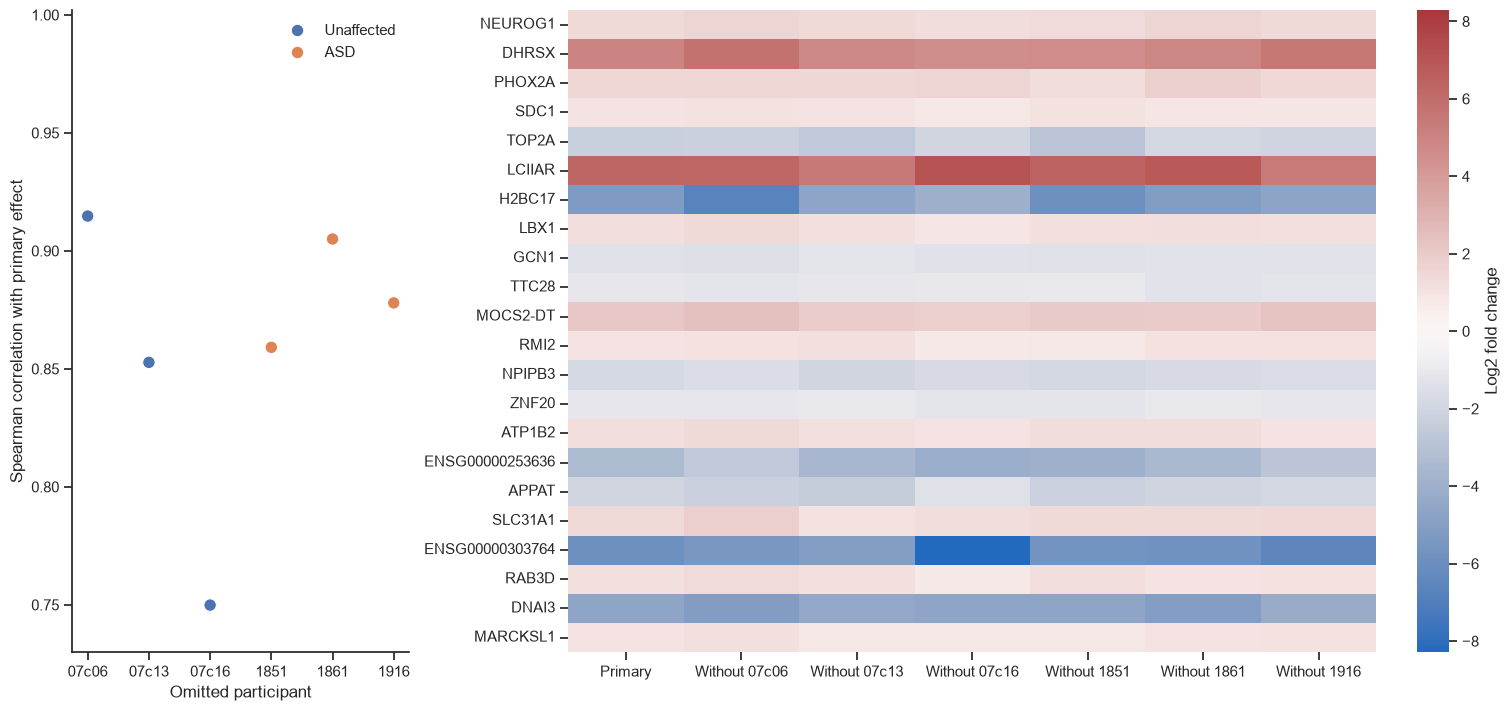

In [7]:
# Visualize participant-deletion stability.

heatmap = pd.concat(
    [leading_primary.rename('Primary'), leading_leave_one_out],
    axis = 1,
).loc[leading_sensitivity.index]
heatmap.columns = [
    'Primary',
    *[f'Without {sample_id}' for sample_id in heatmap.columns[1:]],
]
heatmap.index = leading_sensitivity['geneName'].fillna(
    leading_sensitivity.index.to_series()
)
color_limit = np.nanmax(np.abs(heatmap.to_numpy()))

figure, axes = plt.subplots(
    1,
    2,
    figsize = (15, 7),
    gridspec_kw = {'width_ratios': [1, 2.4]},
    constrained_layout = True,
)
sns.scatterplot(
    data = leave_one_out_summary,
    x = 'omittedParticipantId',
    y = 'spearmanRho',
    hue = 'omittedCondition',
    s = 80,
    ax = axes[0],
)
axes[0].set(
    xlabel = 'Omitted participant',
    ylabel = 'Spearman correlation with primary effect',
    ylim = (
        max(0, leave_one_out_summary['spearmanRho'].min() - 0.02),
        1.002,
    ),
)
axes[0].legend(title = '', frameon = False)

sns.heatmap(
    heatmap,
    cmap = 'vlag',
    center = 0,
    vmin = -color_limit,
    vmax = color_limit,
    cbar_kws = {'label': 'Log2 fold change'},
    ax = axes[1],
)
axes[1].set(xlabel = '', ylabel = '')

sns.despine(ax = axes[0])
plt.show()


In [8]:
# Compare the primary fraction-wise normalization with joint normalization.

_, joint_result = fit_redistribution(
    counts,
    metadata,
    normalization = 'joint',
)
joint = joint_result.table.set_index('geneId')
normalization_sensitivity = pd.DataFrame({
    'geneName': primary['geneName'],
    'fractionWiseLog2FoldChange': primary['log2FoldChange'],
    'jointLog2FoldChange': joint['log2FoldChange'],
    'fractionWiseStatistic': primary['statistic'],
    'jointStatistic': joint['statistic'],
    'primaryWorkingModelAdjustedPValue': primary['adjustedPValue'],
})
normalization_sensitivity['absoluteLog2FoldChangeDifference'] = (
    normalization_sensitivity['jointLog2FoldChange']
    - normalization_sensitivity['fractionWiseLog2FoldChange']
).abs()
normalization_sensitivity['directionConcordant'] = np.sign(
    normalization_sensitivity['fractionWiseLog2FoldChange']
).eq(np.sign(normalization_sensitivity['jointLog2FoldChange']))

normalization_summary = pd.DataFrame({
    'genes': [len(normalization_sensitivity)],
    'spearmanRho': [spearmanr(
        normalization_sensitivity['fractionWiseLog2FoldChange'],
        normalization_sensitivity['jointLog2FoldChange'],
    ).statistic],
    'medianAbsoluteLog2FoldChangeDifference': [
        normalization_sensitivity['absoluteLog2FoldChangeDifference'].median()
    ],
    'directionConcordance': [
        normalization_sensitivity['directionConcordant'].mean()
    ],
    'leadingDirectionConcordance': [
        normalization_sensitivity.loc[
            leading_ids,
            'directionConcordant',
        ].mean()
    ],
})
display(normalization_summary)


,genes,spearmanRho,medianAbsoluteLog2FoldChangeDifference,directionConcordance,leadingDirectionConcordance
0,20470,0.999919,0.046673,0.961847,1.0


In [9]:
# Enumerate complementary label pairs under working participant exchangeability.

reference_anchor = metadata.index[metadata['condition'].eq(REFERENCE)][0]
candidate_ids = [
    sample_id for sample_id in sample_ids if sample_id != reference_anchor
]
test_size = int(metadata['condition'].eq(TEST).sum())
test_partitions = [
    frozenset(partition)
    for partition in combinations(candidate_ids, test_size)
]
observed_test = frozenset(metadata.index[metadata['condition'].eq(TEST)])

if len(test_partitions) != 10:
    raise ValueError('Expected 10 unique two-sided label partitions.')
if sum(partition == observed_test for partition in test_partitions) != 1:
    raise ValueError('The observed labels are not represented exactly once.')


def permuted_metadata(test_participants: frozenset[str]) -> pd.DataFrame:
    frame = metadata.copy()
    frame['condition'] = np.where(
        frame.index.isin(test_participants),
        TEST,
        REFERENCE,
    )
    frame['condition'] = pd.Categorical(
        frame['condition'],
        categories = [REFERENCE, TEST],
    )
    return frame


permutation_records = []

for position, test_participants in enumerate(test_partitions, start = 1):
    observed = test_participants == observed_test
    if observed:
        statistic = primary['statistic']
    else:
        _, result = fit_redistribution(
            counts,
            permuted_metadata(test_participants),
            normalization = 'fraction',
        )
        statistic = result.table.set_index('geneId')['statistic']

    if not np.isfinite(statistic).all():
        raise ValueError('A label partition produced nonfinite statistics.')

    reference_participants = [
        sample_id
        for sample_id in sample_ids
        if sample_id not in test_participants
    ]
    ordered_test = [
        sample_id for sample_id in sample_ids if sample_id in test_participants
    ]
    permutation_records.append({
        'partitionId': f'partition{position:02d}',
        'testParticipants': ';'.join(ordered_test),
        'referenceParticipants': ';'.join(reference_participants),
        'observedAssignment': observed,
        'meanSquaredStatistic': np.mean(np.square(statistic)),
    })

permutation_summary = pd.DataFrame(permutation_records)
observed_global = permutation_summary.loc[
    permutation_summary['observedAssignment'],
    'meanSquaredStatistic',
].item()
global_p = permutation_summary['meanSquaredStatistic'].ge(observed_global).mean()
observed_rank = permutation_summary['meanSquaredStatistic'].rank(
    method = 'min',
    ascending = False,
).loc[permutation_summary['observedAssignment']].item()
permutation_summary['globalPermutationP'] = global_p
permutation_summary['minimumAttainableP'] = 1 / len(permutation_summary)

global_summary = pd.DataFrame({
    'uniqueTwoSidedPartitions': [len(permutation_summary)],
    'observedRank': [int(observed_rank)],
    'globalPermutationP': [global_p],
    'minimumAttainableP': [1 / len(permutation_summary)],
})
display(global_summary)
display(permutation_summary.sort_values('meanSquaredStatistic', ascending = False))


,uniqueTwoSidedPartitions,observedRank,globalPermutationP,minimumAttainableP
0,10,4,0.4,0.1


,partitionId,testParticipants,referenceParticipants,observedAssignment,meanSquaredStatistic,globalPermutationP,minimumAttainableP
0,partition01,07c13;07c16;1851,07c06;1861;1916,False,2.568778,0.4,0.1
6,partition07,07c16;1851;1861,07c06;07c13;1916,False,1.912691,0.4,0.1
5,partition06,07c13;1861;1916,07c06;07c16;1851,False,1.755661,0.4,0.1
9,partition10,1851;1861;1916,07c06;07c13;07c16,True,1.383698,0.4,0.1
2,partition03,07c13;07c16;1916,07c06;1851;1861,False,1.358993,0.4,0.1
1,partition02,07c13;07c16;1861,07c06;1851;1916,False,1.341131,0.4,0.1
7,partition08,07c16;1851;1916,07c06;07c13;1861,False,1.291035,0.4,0.1
4,partition05,07c13;1851;1916,07c06;07c16;1861,False,1.077122,0.4,0.1
8,partition09,07c16;1861;1916,07c06;07c13;1851,False,0.980893,0.4,0.1
3,partition04,07c13;1851;1861,07c06;07c16;1916,False,0.935665,0.4,0.1


In [10]:
# Verify complementary-label direction and numerical symmetry.

complement_test = frozenset(
    metadata.index[metadata['condition'].eq(REFERENCE)]
)
_, complement_result = fit_redistribution(
    counts,
    permuted_metadata(complement_test),
    normalization = 'fraction',
)
complement = complement_result.table.set_index('geneId')
lfc_error = complement['log2FoldChange'] + primary['log2FoldChange']
statistic_error = complement['statistic'] + primary['statistic']
lfc_sign_agreement = np.sign(complement['log2FoldChange']).eq(
    -np.sign(primary['log2FoldChange'])
).mean()
statistic_sign_agreement = np.sign(complement['statistic']).eq(
    -np.sign(primary['statistic'])
).mean()
lfc_rho = spearmanr(
    complement['log2FoldChange'],
    -primary['log2FoldChange'],
).statistic
statistic_rho = spearmanr(
    complement['statistic'],
    -primary['statistic'],
).statistic
leading_lfc_error = lfc_error.loc[leading_ids].abs().max()

if lfc_sign_agreement != 1 or statistic_sign_agreement != 1:
    raise ValueError('Complementary labels did not reverse every direction.')
if lfc_rho < 0.999 or statistic_rho < 0.999:
    raise ValueError('Complementary-label ranks are not numerically stable.')
if lfc_error.abs().quantile(0.99) > 0.01:
    raise ValueError('Complementary-label effects show excessive numerical drift.')
if leading_lfc_error > 0.05:
    raise ValueError('A leading effect is unstable under complementary labels.')

symmetry_summary = pd.DataFrame({
    'log2FoldChangeSignAgreement': [lfc_sign_agreement],
    'statisticSignAgreement': [statistic_sign_agreement],
    'log2FoldChangeSpearmanRho': [lfc_rho],
    'statisticSpearmanRho': [statistic_rho],
    'medianAbsoluteLog2FoldChangeError': [lfc_error.abs().median()],
    'percentile99AbsoluteLog2FoldChangeError': [
        lfc_error.abs().quantile(0.99)
    ],
    'maximumAbsoluteLog2FoldChangeError': [lfc_error.abs().max()],
    'maximumAbsoluteStatisticError': [statistic_error.abs().max()],
    'maximumLeadingAbsoluteLog2FoldChangeError': [leading_lfc_error],
})
display(symmetry_summary)


,log2FoldChangeSignAgreement,statisticSignAgreement,log2FoldChangeSpearmanRho,statisticSpearmanRho,medianAbsoluteLog2FoldChangeError,percentile99AbsoluteLog2FoldChangeError,maximumAbsoluteLog2FoldChangeError,maximumAbsoluteStatisticError,maximumLeadingAbsoluteLog2FoldChangeError
0,1.0,1.0,0.999953,0.999973,6.301032e-07,0.0012,4.376139,0.526182,0.001061


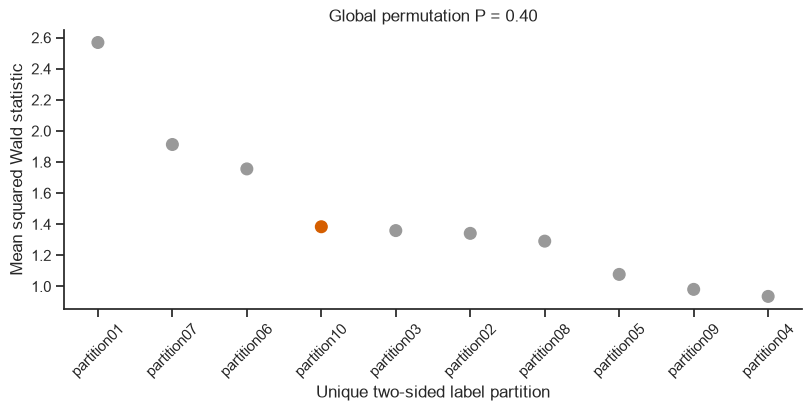

In [11]:
# Visualize the exact global label diagnostic.

plot_table = permutation_summary.sort_values(
    'meanSquaredStatistic',
    ascending = False,
)
colors = np.where(plot_table['observedAssignment'], '#D55E00', '#999999')

figure, ax = plt.subplots(figsize = (8, 4), constrained_layout = True)
ax.scatter(
    plot_table['partitionId'],
    plot_table['meanSquaredStatistic'],
    c = colors,
    s = 70,
)
ax.set(
    xlabel = 'Unique two-sided label partition',
    ylabel = 'Mean squared Wald statistic',
    title = f'Global permutation P = {global_p:.2f}',
)
ax.tick_params(axis = 'x', rotation = 45)
sns.despine()
plt.show()


In [12]:
# Save complete sensitivity outputs.

leave_one_out.to_csv(
    RESULTS_DIR / 'redistributionLeaveOneOut.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
leave_one_out_summary.to_csv(
    RESULTS_DIR / 'redistributionSensitivitySummary.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
leading_sensitivity.reset_index().to_csv(
    RESULTS_DIR / 'redistributionLeadingGeneSensitivity.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
normalization_sensitivity.reset_index().to_csv(
    RESULTS_DIR / 'normalizationSensitivity.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
permutation_summary.to_csv(
    RESULTS_DIR / 'redistributionPermutationSummary.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
global_summary.to_csv(
    RESULTS_DIR / 'redistributionPermutationGlobal.tsv',
    sep = '\t',
    index = False,
)
symmetry_summary.to_csv(
    RESULTS_DIR / 'redistributionSymmetrySummary.tsv',
    sep = '\t',
    index = False,
)
joint_result.write(
    RESULTS_DIR / 'polysomeMonosomeJointNormalization.tsv'
)
